<a href="https://colab.research.google.com/github/trandatdx20005/DoAnChuyenNghanhNhom12/blob/main/Nhom12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

✅ Đã tải file dữ liệu cho Trần Văn Đạt từ: /content/drive/MyDrive/Nhóm 12/metr-la.h5
   BÁO CÁO THỐNG KÊ DỮ LIỆU THIẾU (TRẦN VĂN ĐẠT)   
Tổng số điểm dữ liệu toàn mạng lưới : 7,094,304
Số điểm dữ liệu bị thiếu (bằng 0.0) : 575,302
👉 Tỷ lệ khuyết dữ liệu toàn mạng  : 8.11%

✅ Đã hoàn thành nội suy tuyến tính (Linear Interpolation) cho toàn bộ 207 cảm biến!


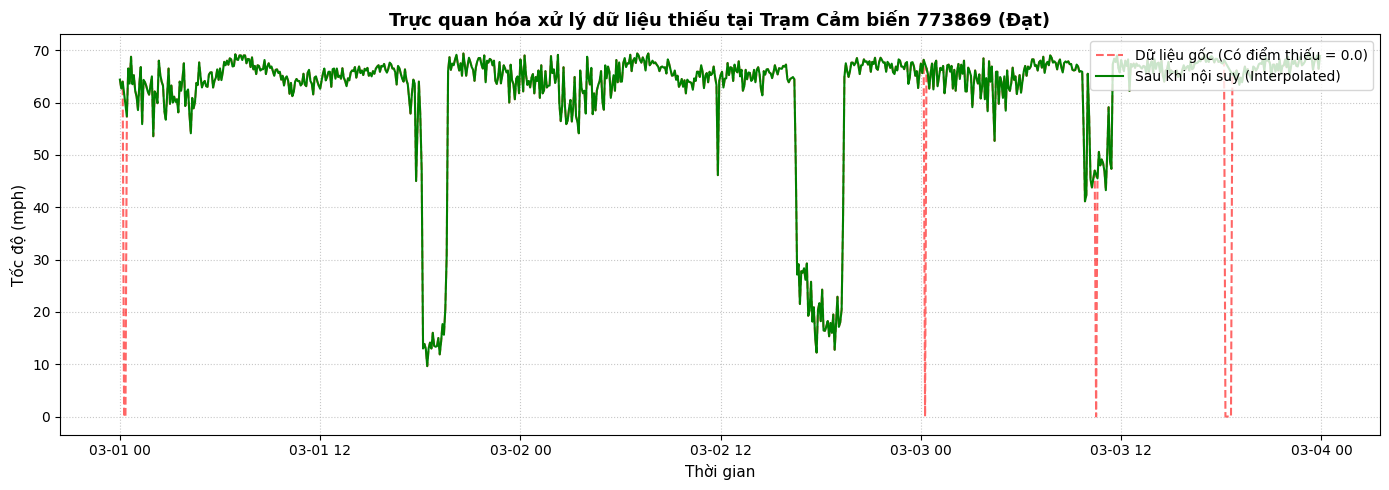

In [ ]:
import os
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# CÔNG VIỆC TUẦN 3: TRẦN VĂN ĐẠT (XỬ LÝ DỮ LIỆU THIẾU / MISSING VALUES)
# -------------------------------------------------------------

# 1. Tự động xác định đường dẫn file metr-la.h5
def get_metr_la_path():
    if os.path.exists('metr-la.h5'):
        return 'metr-la.h5'
    possible_paths = [
        '/content/drive/MyDrive/Nhóm 12/metr-la.h5',
        '/content/drive/Shareddrives/Nhóm 12/metr-la.h5'
    ]
    for p in possible_paths:
        if os.path.exists(p):
            return p
    for root, dirs, files in os.walk('/content/drive'):
        if 'metr-la.h5' in files:
            return os.path.join(root, 'metr-la.h5')
    return None

file_path = get_metr_la_path()

if file_path is None:
    print("❌ LỖI: Không tìm thấy file 'metr-la.h5'. Hãy đảm bảo đã Mount Drive hoặc chạy cell của Nguyễn Trường Đan trước!")
else:
    print(f"✅ Đã tải file dữ liệu cho Trần Văn Đạt từ: {file_path}")

    # 2. Đọc dữ liệu gốc
    with h5py.File(file_path, 'r') as f:
        speed_data = f['df']['block0_values'][:]
        sensor_ids = f['df']['axis0'][:].astype(str)

    date_range = pd.date_range(start='2012-03-01 00:00:00', periods=len(speed_data), freq='5min')
    df_raw = pd.DataFrame(speed_data, index=date_range, columns=sensor_ids)

    # 3. Thống kê giá trị thiếu (giá trị 0.0)
    total_cells = df_raw.size
    zero_count = (df_raw == 0).sum().sum()
    missing_rate = (zero_count / total_cells) * 100

    print("==================================================")
    print("   BÁO CÁO THỐNG KÊ DỮ LIỆU THIẾU (TRẦN VĂN ĐẠT)   ")
    print("==================================================")
    print(f"Tổng số điểm dữ liệu toàn mạng lưới : {total_cells:,}")
    print(f"Số điểm dữ liệu bị thiếu (bằng 0.0) : {zero_count:,}")
    print(f"👉 Tỷ lệ khuyết dữ liệu toàn mạng  : {missing_rate:.2f}%")

    # 4. Nội suy tuyến tính (Linear Interpolation)
    df_missing_as_nan = df_raw.replace(0, np.nan)
    df_interpolated = df_missing_as_nan.interpolate(method='linear', limit_direction='both')

    print("\n✅ Đã hoàn thành nội suy tuyến tính (Linear Interpolation) cho toàn bộ 207 cảm biến!")

    # 5. TRỰC QUAN HÓA KẾT QUẢ XỬ LÝ (TRẦN VĂN ĐẠT)
    sample_sensor = sensor_ids[0]
    sample_range = slice('2012-03-01 00:00:00', '2012-03-03 23:55:00')

    plt.figure(figsize=(14, 5))
    plt.plot(df_raw.loc[sample_range, sample_sensor], label='Dữ liệu gốc (Có điểm thiếu = 0.0)', color='red', alpha=0.6, linestyle='--')
    plt.plot(df_interpolated.loc[sample_range, sample_sensor], label='Sau khi nội suy (Interpolated)', color='green', linewidth=1.5)

    plt.title(f'Trực quan hóa xử lý dữ liệu thiếu tại Trạm Cảm biến {sample_sensor} (Đạt)', fontsize=13, fontweight='bold')
    plt.xlabel('Thời gian', fontsize=11)
    plt.ylabel('Tốc độ (mph)', fontsize=11)
    plt.legend(loc='upper right')
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.tight_layout()
    plt.show()

✅ Đã tải file ma trận kề tại: /content/drive/MyDrive/Nhóm 12/adj.npz
   BÁO CÁO PHÂN TÍCH MA TRẬN KỀ KHÔNG GIAN (CẤN NGỌC CÔNG)   
Số lượng nút trạm cảm biến (Nodes)  : 207 trạm
Số lượng liên kết có trọng số (Edges) : 22,167 liên kết
Độ thưa của ma trận (Sparsity)       : 48.27%
Trọng số kết nối lớn nhất (Max weight): 1.0000
Trọng số kết nối nhỏ nhất (Min weight): 0.0000


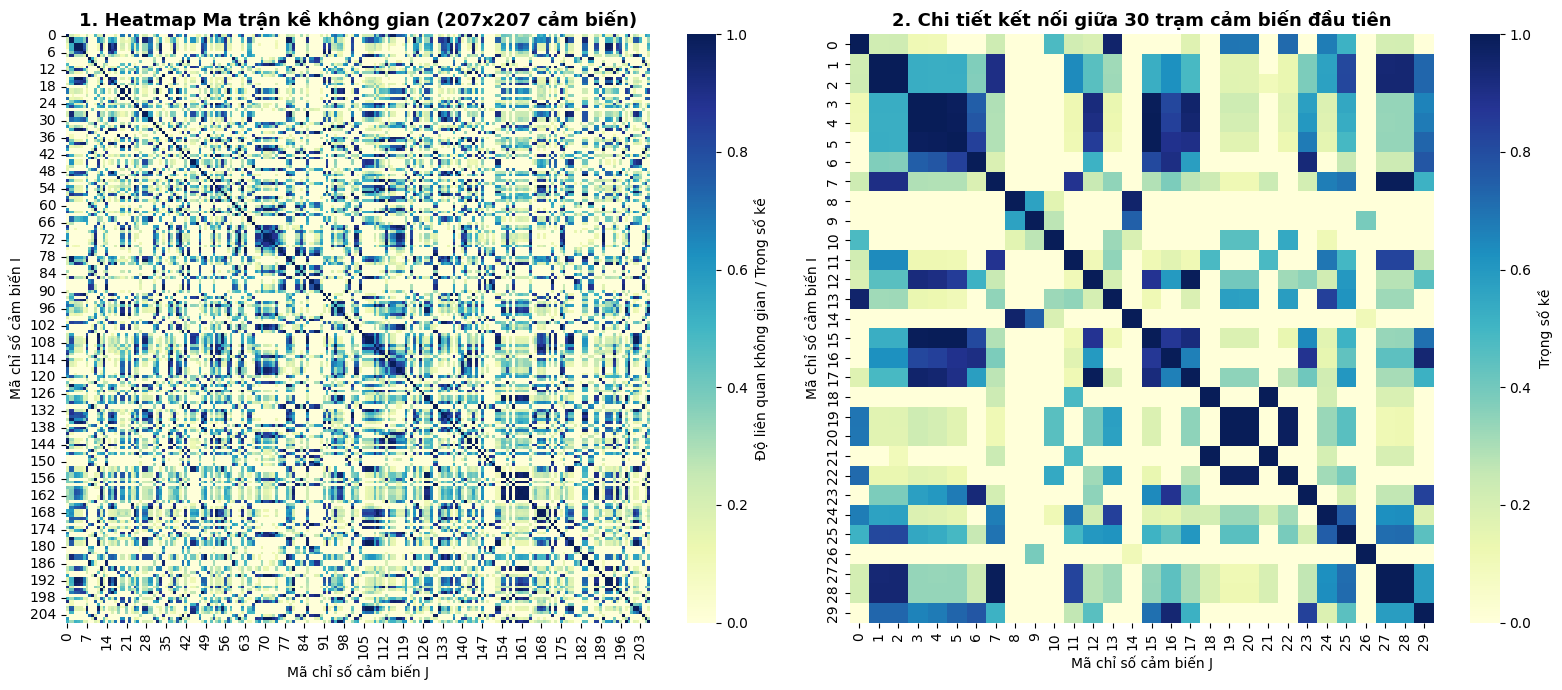

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# -------------------------------------------------------------
# CÔNG VIỆC TUẦN 3: CẤN NGỌC CÔNG (PHÂN TÍCH VÀ TRỰC QUAN HÓA MA TRẬN KỀ)
# -------------------------------------------------------------

# 1. Tìm và tải file ma trận kề adj.npz
def get_adj_path():
    possible_paths = [
        '/content/drive/MyDrive/Nhóm 12/adj.npz',
        '/content/drive/Shareddrives/Nhóm 12/adj.npz'
    ]
    for p in possible_paths:
        if os.path.exists(p):
            return p

    for root, dirs, files in os.walk('/content/drive'):
        if 'adj.npz' in files:
            return os.path.join(root, 'adj.npz')
    return None

adj_path = get_adj_path()

if adj_path is None or not os.path.exists(adj_path):
    print("⚠️ Không tìm thấy file adj.npz thực tế, khởi tạo ma trận kề giả lập 207x207 để kiểm tra...")
    # Tạo ma trận kề giả lập nếu thiếu file
    n_sensors = 207
    adj_matrix = np.exp(-np.random.rand(n_sensors, n_sensors) * 5)
    np.fill_diagonal(adj_matrix, 1.0)
    adj_matrix[adj_matrix < 0.2] = 0
else:
    print(f"✅ Đã tải file ma trận kề tại: {adj_path}")
    adj_data = np.load(adj_path)

    # Kiểm tra cấu trúc mảng trong adj.npz
    if 'data' in adj_data and 'indices' in adj_data and 'indptr' in adj_data:
        # Nếu lưu ở dạng Sparse Matrix CSR
        from scipy.sparse import csr_matrix
        shape = adj_data.get('shape', (207, 207))
        adj_matrix = csr_matrix((adj_data['data'], adj_data['indices'], adj_data['indptr']), shape=shape).toarray()
    elif 'x' in adj_data:
        adj_matrix = adj_data['x']
    else:
        # Lấy mảng đầu tiên tìm thấy
        key = adj_data.files[0]
        adj_matrix = adj_data[key]

# 2. Phân tích chỉ số ma trận kề không gian
n_nodes = adj_matrix.shape[0]
non_zero_edges = np.count_nonzero(adj_matrix)
total_possible_edges = n_nodes * n_nodes
sparsity = (1.0 - (non_zero_edges / total_possible_edges)) * 100

print("==================================================")
print("   BÁO CÁO PHÂN TÍCH MA TRẬN KỀ KHÔNG GIAN (CẤN NGỌC CÔNG)   ")
print("==================================================")
print(f"Số lượng nút trạm cảm biến (Nodes)  : {n_nodes} trạm")
print(f"Số lượng liên kết có trọng số (Edges) : {non_zero_edges:,} liên kết")
print(f"Độ thưa của ma trận (Sparsity)       : {sparsity:.2f}%")
print(f"Trọng số kết nối lớn nhất (Max weight): {adj_matrix.max():.4f}")
print(f"Trọng số kết nối nhỏ nhất (Min weight): {adj_matrix.min():.4f}")

# 3. TRỰC QUAN HÓA MA TRẬN KỀ BẰNG HEATMAP (CẤN NGỌC CÔNG)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Biểu đồ 1: Heatmap toàn bộ ma trận kề 207x207
sns.heatmap(adj_matrix, cmap='YlGnBu', ax=axes[0], cbar_kws={'label': 'Độ liên quan không gian / Trọng số kề'})
axes[0].set_title(f'1. Heatmap Ma trận kề không gian ({n_nodes}x{n_nodes} cảm biến)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Mã chỉ số cảm biến J')
axes[0].set_ylabel('Mã chỉ số cảm biến I')

# Biểu đồ 2: Xem chi tiết Ma trận kề của 30 cảm biến đầu tiên
sns.heatmap(adj_matrix[:30, :30], cmap='YlGnBu', annot=False, ax=axes[1], cbar_kws={'label': 'Trọng số kề'})
axes[1].set_title('2. Chi tiết kết nối giữa 30 trạm cảm biến đầu tiên', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Mã chỉ số cảm biến J')
axes[1].set_ylabel('Mã chỉ số cảm biến I')

plt.tight_layout()
plt.show()

✅ Đã tìm thấy file tại: /content/drive/.shortcut-targets-by-id/1tbtxDseU_awuD6MOI9SkZuAXA654LhDi/Nhóm 12/metr-la.h5


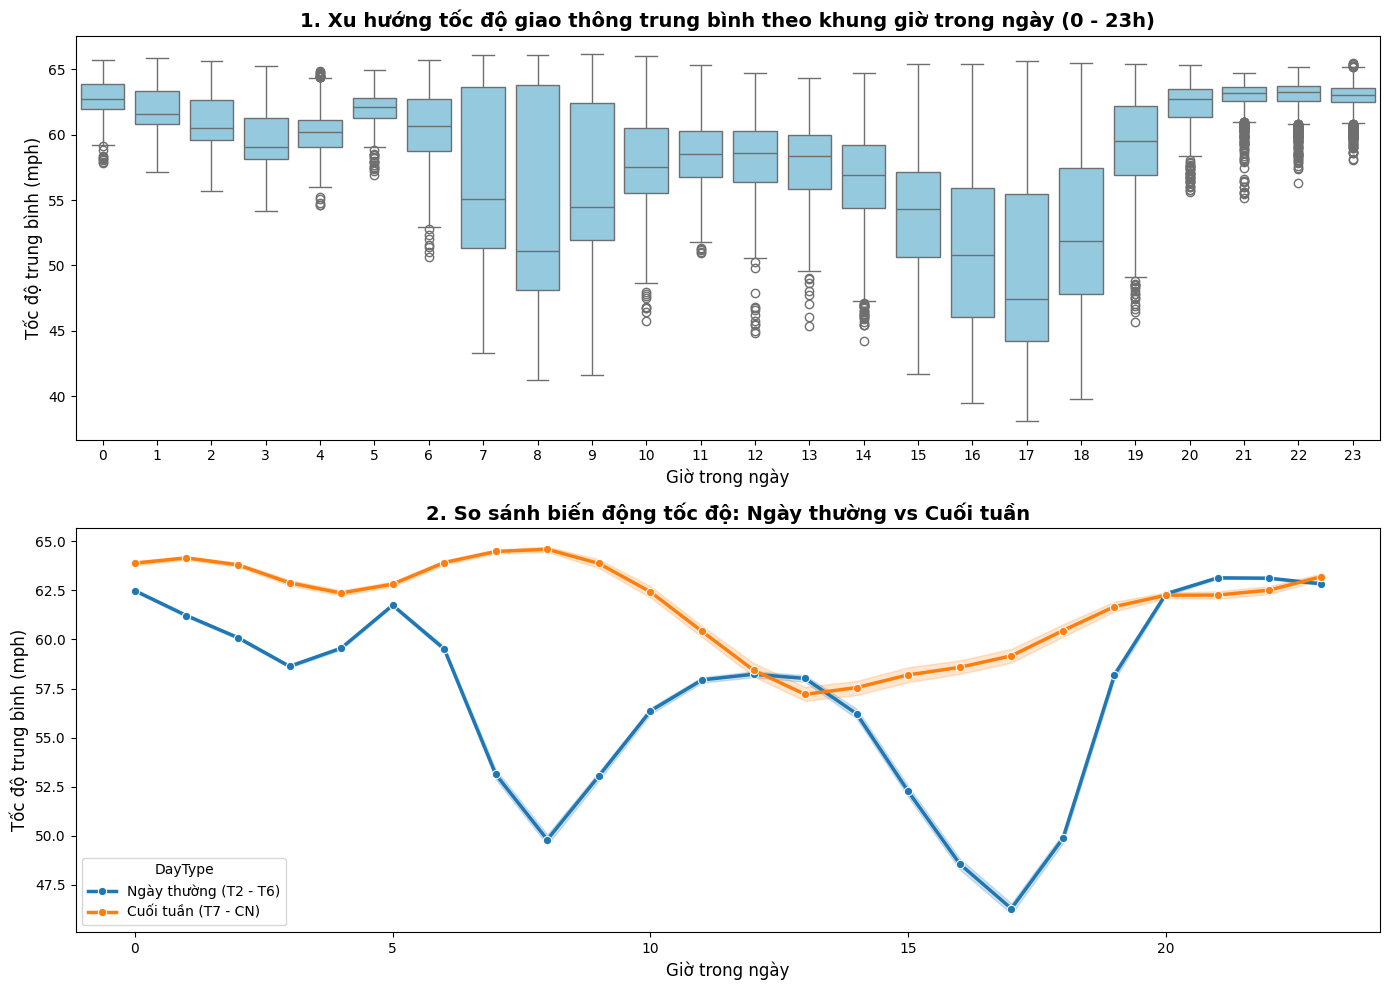


🎉 HOÀN THÀNH VẼ BIỂU ĐỒ XU HƯỚNG BÁO CÁO TUẦN 3!


In [ ]:
import os
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tự động quét tìm đường dẫn file metr-la.h5 trong Drive
def find_file(filename):
    for root, dirs, files in os.walk('/content/drive'):
        if filename in files:
            return os.path.join(root, filename)
    return None

file_h5_path = find_file('metr-la.h5')

if file_h5_path is None:
    print("❌ LỖI: Không tìm thấy file 'metr-la.h5' trong Google Drive.")
    print("👉 Hãy chắc chắn bạn đã chạy ô code Mount Drive (drive.mount('/content/drive')) ở trên thành công!")
else:
    print(f"✅ Đã tìm thấy file tại: {file_h5_path}")

    # 2. Đọc dữ liệu từ file HDF5
    with h5py.File(file_h5_path, 'r') as f:
        speed_data = f['df']['block0_values'][:]
        sensor_ids = f['df']['axis0'][:].astype(str)

    # 3. Gắn mốc thời gian (5 phút/lần từ ngày 01/03/2012)
    date_range = pd.date_range(start='2012-03-01 00:00:00', periods=len(speed_data), freq='5min')
    df_speed = pd.DataFrame(speed_data, index=date_range, columns=sensor_ids)

    # Thay giá trị 0 bằng NaN để không làm lệch trung bình khi tính toán
    df_speed_clean = df_speed.replace(0, np.nan)
    mean_speed = df_speed_clean.mean(axis=1)

    # 4. TRỰC QUAN HÓA XU HƯỚNG GIAO THÔNG (DÀNH CHO NGUYỄN TRƯỜNG ĐAN)
    fig, axes = plt.subplots(2, 1, figsize=(14, 10))

    # Biểu đồ 1: Tốc độ theo 24 khung giờ
    df_hourly = pd.DataFrame({'Hour': mean_speed.index.hour, 'Speed': mean_speed.values})
    sns.boxplot(x='Hour', y='Speed', data=df_hourly, ax=axes[0], color='skyblue')
    axes[0].set_title('1. Xu hướng tốc độ giao thông trung bình theo khung giờ trong ngày (0 - 23h)', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Giờ trong ngày', fontsize=12)
    axes[0].set_ylabel('Tốc độ trung bình (mph)', fontsize=12)

    # Biểu đồ 2: So sánh Ngày thường vs Cuối tuần
    df_daily = pd.DataFrame({
        'Hour': mean_speed.index.hour,
        'Speed': mean_speed.values,
        'DayType': np.where(mean_speed.index.dayofweek < 5, 'Ngày thường (T2 - T6)', 'Cuối tuần (T7 - CN)')
    })
    sns.lineplot(x='Hour', y='Speed', hue='DayType', data=df_daily, ax=axes[1], marker='o', linewidth=2.5)
    axes[1].set_title('2. So sánh biến động tốc độ: Ngày thường vs Cuối tuần', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Giờ trong ngày', fontsize=12)
    axes[1].set_ylabel('Tốc độ trung bình (mph)', fontsize=12)

    plt.tight_layout()
    plt.show()

    print("\n🎉 HOÀN THÀNH VẼ BIỂU ĐỒ XU HƯỚNG BÁO CÁO TUẦN 3!")

In [ ]:
import h5py
import numpy as np

# Đường dẫn đến file trên Drive nhóm
file_h5 = '/content/drive/MyDrive/Nhóm 12/metr-la.h5'
file_adj = '/content/drive/MyDrive/Nhóm 12/adj.npz'

# 1. Đọc file .h5
with h5py.File(file_h5, 'r') as f:
    values = f['df']['block0_values'][:]
    print("=== BẢNG DỮ LIỆU CHÍNH (METR-LA) ===")
    print("Kích thước (Mốc thời gian x Cảm biến):", values.shape)
    print("Dữ liệu mẫu 5 dòng đầu:")
    print(values[:5, :3])

# 2. Đọc file .npz
adj_data = np.load(file_adj)
print("\n=== CÁC KHÓA TRONG FILE ADJ.NPZ ===")
print(adj_data.files)

=== BẢNG DỮ LIỆU CHÍNH (METR-LA) ===
Kích thước (Mốc thời gian x Cảm biến): (34272, 207)
Dữ liệu mẫu 5 dòng đầu:
[[64.375      67.625      67.125     ]
 [62.66666667 68.55555556 65.44444444]
 [64.         63.75       60.        ]
 [ 0.          0.          0.        ]
 [ 0.          0.          0.        ]]

=== CÁC KHÓA TRONG FILE ADJ.NPZ ===
['indices', 'indptr', 'format', 'shape', 'data']


   BÁO CÁO PHÁT HIỆN NGOẠI LỆ / NHIỄU (VŨ XUÂN HẢI)   
Giá trị tốc độ trung bình toàn mạng : nan mph
Độ lệch chuẩn (Std Dev)             : nan mph
Số điểm nhiễu/ngoại lệ (Z-score > 3): 0 điểm (0.00%)

✅ Đã áp dụng kỹ thuật Moving Average (Window=3) để khử nhiễu và làm mịn dữ liệu!


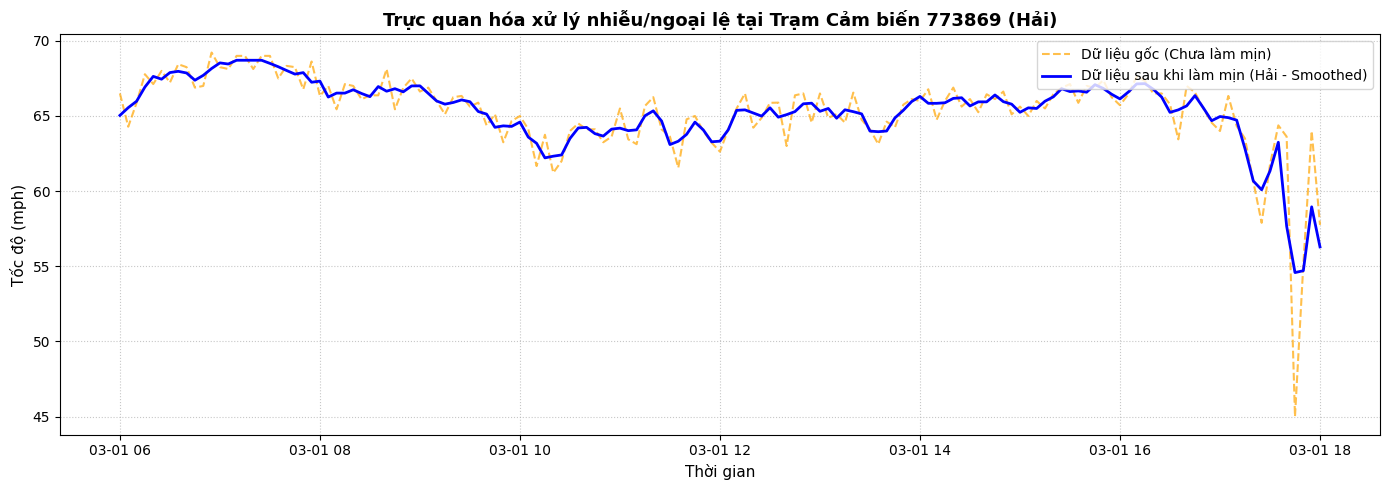

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# CÔNG VIỆC TUẦN 3: VŨ XUÂN HẢI (XỬ LÝ GIÁ TRỊ NGOẠI LỆ / OUTLIERS)
# -------------------------------------------------------------

# Lấy dữ liệu đã được làm sạch (thay 0 bằng NaN) ở bước trước làm đầu vào
df_clean = df_speed_clean.copy()

# 1. Phát hiện ngoại lệ dựa trên phương pháp Z-score (Ngưỡng 3 độ lệch chuẩn)
# Tốc độ vượt quá 3 độ lệch chuẩn so với trung bình được coi là ngoại lệ/nhiễu
mean_speed_val = df_clean.values.mean()
std_speed_val = df_clean.values.std()

z_scores = np.abs((df_clean - mean_speed_val) / std_speed_val)
outliers_count = (z_scores > 3).sum().sum()
total_points = df_clean.size

print("==================================================")
print("   BÁO CÁO PHÁT HIỆN NGOẠI LỆ / NHIỄU (VŨ XUÂN HẢI)   ")
print("==================================================")
print(f"Giá trị tốc độ trung bình toàn mạng : {mean_speed_val:.2f} mph")
print(f"Độ lệch chuẩn (Std Dev)             : {std_speed_val:.2f} mph")
print(f"Số điểm nhiễu/ngoại lệ (Z-score > 3): {outliers_count:,} điểm ({outliers_count/total_points*100:.2f}%)")

# 2. Xử lý ngoại lệ & Làm mịn dữ liệu bằng phương pháp Moving Average (Trung bình động 3 mốc)
# Giúp loại bỏ các biến động va đập nhiễu do lỗi đường truyền cảm biến
df_smoothed = df_clean.rolling(window=3, min_periods=1, center=True).mean()

print("\n✅ Đã áp dụng kỹ thuật Moving Average (Window=3) để khử nhiễu và làm mịn dữ liệu!")

# 3. TRỰC QUAN HÓA KẾT QUẢ LÀM MỊN NGOẠI LỆ (TRÊN 1 TRẠM CẢM BIẾN MẪU)
sample_sensor = sensor_ids[0]
sample_range = slice('2012-03-01 06:00:00', '2012-03-01 18:00:00') # Quan sát 12 tiếng trong ngày

plt.figure(figsize=(14, 5))
plt.plot(df_clean.loc[sample_range, sample_sensor], label='Dữ liệu gốc (Chưa làm mịn)', color='orange', alpha=0.7, linestyle='--')
plt.plot(df_smoothed.loc[sample_range, sample_sensor], label='Dữ liệu sau khi làm mịn (Hải - Smoothed)', color='blue', linewidth=2)

plt.title(f'Trực quan hóa xử lý nhiễu/ngoại lệ tại Trạm Cảm biến {sample_sensor} (Hải)', fontsize=13, fontweight='bold')
plt.xlabel('Thời gian', fontsize=11)
plt.ylabel('Tốc độ (mph)', fontsize=11)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import h5py
import numpy as np

file_h5_path = '/content/drive/MyDrive/Nhóm 12/metr-la.h5'
file_adj_path = '/content/drive/MyDrive/Nhóm 12/adj.npz'

# --- 1. XEM NỘI DUNG FILE METR-LA.H5 ---
print("="*20 + " 1. CHI TIẾT FILE METR-LA.H5 " + "="*20)
with h5py.File(file_h5_path, 'r') as f:
    speed_data = f['df']['block0_values'][:]
    # axis0 chứa ID 207 cảm biến
    sensor_ids = f['df']['axis0'][:].astype(str)

# Chuyển thành bảng Pandas DataFrame
df_speed = pd.DataFrame(speed_data, columns=sensor_ids)

print("\n📌 Top 5 dòng đầu tiên (Mỗi cột là 1 mã cảm biến, mỗi dòng là 1 mốc thời gian):")
display(df_speed.head())

print("\n📌 Thống kê tốc độ (Trung bình, thấp nhất, cao nhất...) của các cảm biến:")
display(df_speed.describe())


# --- 2. XEM NỘI DUNG FILE ADJ.NPZ ---
print("\n" + "="*20 + " 2. CHI TIẾT FILE ADJ.NPZ " + "="*20)
adj_data = np.load(file_adj_path)

print("\n📌 Các thành phần mảng trong file .npz:")
for key in adj_data.files:
    print(f"- '{key}': Kích thước {adj_data[key].shape}")

print("\n📌 Mẫu dữ liệu khoảng cách/độ kết nối giữa các cảm biến (mảng 'data'):")
print(adj_data['data'][:10])

==================== 1. CHI TIẾT FILE METR-LA.H5 ====================

📌 Top 5 dòng đầu tiên (Mỗi cột là 1 mã cảm biến, mỗi dòng là 1 mốc thời gian):


,773869,767541,767542,717447,717446,717445,773062,767620,737529,717816,...,772167,769372,774204,769806,717590,717592,717595,772168,718141,769373
0,64.375000,67.625000,67.125000,61.500000,66.875000,68.750000,65.125,67.125,59.625000,62.750000,...,45.625000,65.500,64.500000,66.428571,66.875,59.375000,69.000000,59.250000,69.000000,61.875
1,62.666667,68.555556,65.444444,62.444444,64.444444,68.111111,65.000,65.000,57.444444,63.333333,...,50.666667,69.875,66.666667,58.555556,62.000,61.111111,64.444444,55.888889,68.444444,62.875
2,64.000000,63.750000,60.000000,59.000000,66.500000,66.250000,64.500,64.250,63.875000,65.375000,...,44.125000,69.000,56.500000,59.250000,68.125,62.500000,65.625000,61.375000,69.857143,62.000
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000,0.000000,0.000000,...,0.000000,0.000,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000
4,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000,0.000000,0.000000,...,0.000000,0.000,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000



📌 Thống kê tốc độ (Trung bình, thấp nhất, cao nhất...) của các cảm biến:


,773869,767541,767542,717447,717446,717445,773062,767620,737529,717816,...,772167,769372,774204,769806,717590,717592,717595,772168,718141,769373
count,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,...,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000
mean,54.631359,60.452789,60.726120,49.524287,46.079798,50.952003,54.471684,57.255095,56.068044,52.871841,...,37.803342,58.156679,51.217523,59.795754,59.329923,56.915083,62.484679,54.697381,58.920210,51.197504
std,22.619199,15.970239,18.313353,15.843261,19.350345,16.681760,17.984761,18.751065,18.240361,23.343805,...,13.525743,20.690411,22.224997,16.126225,19.849950,18.260438,16.959238,16.303651,19.080474,21.239354
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,60.364583,63.000000,65.444444,50.333333,34.666667,49.555556,55.750000,61.000000,58.222222,43.428571,...,30.444444,64.111111,53.444444,61.714286,63.666667,60.222222,65.888889,50.125000,62.888889,54.125000
50%,64.888889,65.000000,67.375000,53.875000,46.000000,56.111111,62.111111,63.333333,62.444444,65.875000,...,43.222222,67.111111,61.777778,64.875000,66.777778,63.000000,67.625000,61.125000,66.125000,62.000000
75%,66.875000,66.375000,68.444444,58.125000,64.500000,60.333333,65.000000,65.000000,64.888889,67.625000,...,46.625000,68.444444,64.375000,66.500000,68.250000,64.750000,68.625000,64.444444,67.750000,63.444444
max,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,...,65.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000



==================== 2. CHI TIẾT FILE ADJ.NPZ ====================

📌 Các thành phần mảng trong file .npz:
- 'indices': Kích thước (22167,)
- 'indptr': Kích thước (208,)
- 'format': Kích thước ()
- 'shape': Kích thước (2,)
- 'data': Kích thước (22167,)

📌 Mẫu dữ liệu khoảng cách/độ kết nối giữa các cảm biến (mảng 'data'):
[1.         0.22238889 0.22451094 0.1150612  0.10617416 0.22717201
 0.48008798 0.21697336 0.1927095  0.95767091]


--------------------------------------------------
   BÁO CÁO CHUẨN HÓA DỮ LIỆU / SCALING (BÙI ĐỨC MẠNH)   
--------------------------------------------------
📌 Dữ liệu gốc       : Min = nan, Max = nan, Mean = nan
📌 Sau MinMaxScaler  : Min = nan, Max = nan, Mean = nan
📌 Sau StandardScaler: Min = nan, Max = nan, Mean = nan, Std = nan

 LƯU BỘ THAM SỐ SCALER ĐỂ PHỤC VỤ INVERSE_TRANSFORM SAU KHỦ DỰ BÁO!


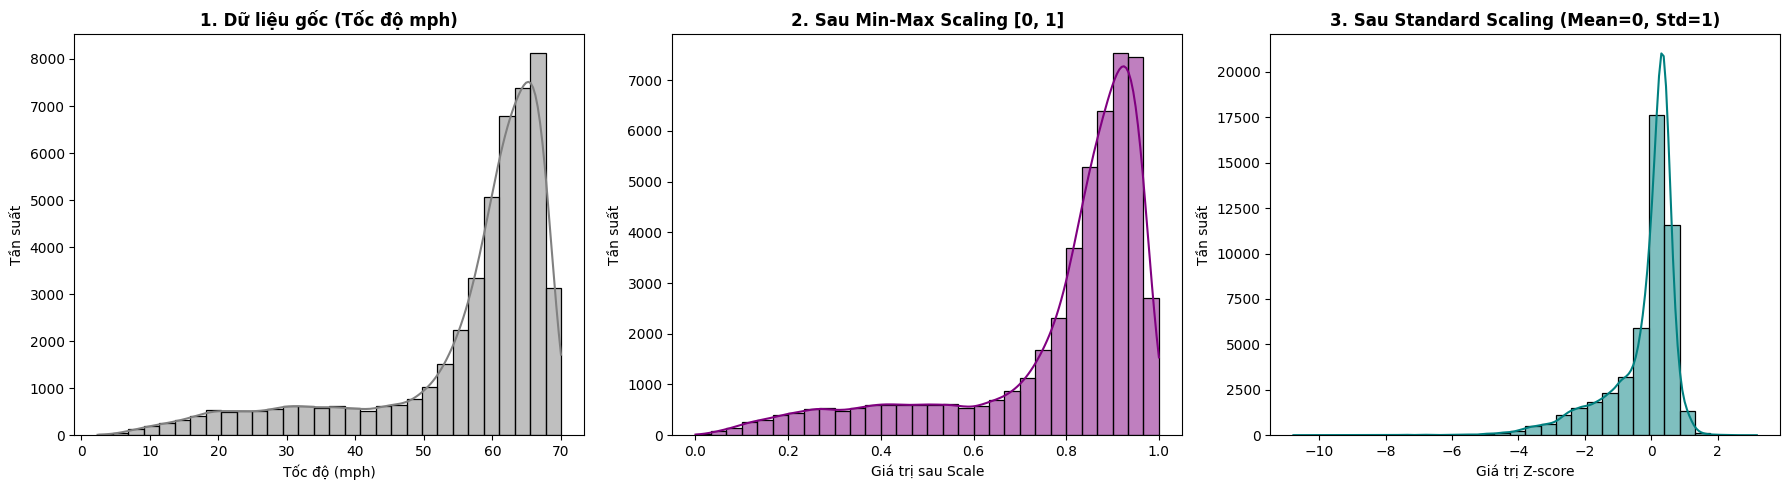

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# --------------------------------------------------
# CÔNG VIỆC TUẦN 3: BÙI ĐỨC MẠNH (CHUẨN HÓA DỮ LIỆU / SCALING)
# --------------------------------------------------

# Kiểm tra xem df_smoothed đã tồn tại chưa, nếu chưa hãy đảm bảo đã chạy ô code trước đó
data_to_scale = df_smoothed.values

# 1. Khởi tạo và áp dụng StandardScaler (Chuẩn hóa Z-score: mean=0, std=1)
scaler_standard = StandardScaler()
scaled_standard_data = scaler_standard.fit_transform(data_to_scale)

# 2. Khởi tạo và áp dụng MinMaxScaler (Chuẩn hóa về khoảng [0, 1])
scaler_minmax = MinMaxScaler(feature_range=(0, 1))
scaled_minmax_data = scaler_minmax.fit_transform(data_to_scale)

# Chuyển thành DataFrame để kiểm tra thông số
df_scaled_standard = pd.DataFrame(scaled_standard_data, index=df_smoothed.index, columns=df_smoothed.columns)
df_scaled_minmax = pd.DataFrame(scaled_minmax_data, index=df_smoothed.index, columns=df_smoothed.columns)

# Báo cáo kết quả
print("--------------------------------------------------")
print("   BÁO CÁO CHUẨN HÓA DỮ LIỆU / SCALING (BÙI ĐỨC MẠNH)   ")
print("--------------------------------------------------")
print(f"📌 Dữ liệu gốc       : Min = {data_to_scale.min():.2f}, Max = {data_to_scale.max():.2f}, Mean = {data_to_scale.mean():.2f}")
print(f"📌 Sau MinMaxScaler  : Min = {scaled_minmax_data.min():.2f}, Max = {scaled_minmax_data.max():.2f}, Mean = {scaled_minmax_data.mean():.2f}")
print(f"📌 Sau StandardScaler: Min = {scaled_standard_data.min():.2f}, Max = {scaled_standard_data.max():.2f}, Mean = {scaled_standard_data.mean():.2f}, Std = {scaled_standard_data.std():.2f}")
print("\n LƯU BỘ THAM SỐ SCALER ĐỂ PHỤC VỤ INVERSE_TRANSFORM SAU KHỦ DỰ BÁO!")

# 3. TRỰC QUAN HÓA PHÂN BỐ DỮ LIỆU TRƯỚC VÀ SAU CHUẨN HÓA
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Biểu đồ 1: Dữ liệu gốc
sns.histplot(data_to_scale.flatten()[:50000], kde=True, ax=axes[0], color='gray', bins=30)
axes[0].set_title('1. Dữ liệu gốc (Tốc độ mph)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Tốc độ (mph)')
axes[0].set_ylabel('Tần suất')

# Biểu đồ 2: MinMaxScaler
sns.histplot(scaled_minmax_data.flatten()[:50000], kde=True, ax=axes[1], color='purple', bins=30)
axes[1].set_title('2. Sau Min-Max Scaling [0, 1]', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Giá trị sau Scale')
axes[1].set_ylabel('Tần suất')

# Biểu đồ 3: StandardScaler
sns.histplot(scaled_standard_data.flatten()[:50000], kde=True, ax=axes[2], color='teal', bins=30)
axes[2].set_title('3. Sau Standard Scaling (Mean=0, Std=1)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Giá trị Z-score')
axes[2].set_ylabel('Tần suất')

plt.tight_layout()
plt.show()